# AI-Powered Energy Consumption Forecasting
## A runnable beginner notebook, backed by the modular pipeline

**Goal:** predict hourly building/household demand, evaluate without future leakage, and explore a hypothetical scheduling decision.

We use a **seeded virtual building** and a separate **public measured UCI household**. No corporate systems or live smart meters are connected. `Energy_kW` means hour-average **power**; one-hour energy is kW × 1 h.

This notebook intentionally imports the same `src/` functions as the CLI/API. It does not maintain a second inconsistent forecasting implementation. The bundled outputs below are actual executed results; a cell explicitly says whether it is reading them or creating them.

**Before first run:** install `requirements-dev.txt` in your virtual environment, then open this notebook in JupyterLab.

In [1]:
from pathlib import Path
import os, sys, json, subprocess

ROOT = Path.cwd().resolve()
while not (ROOT / 'main.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'main.py').exists():
    raise FileNotFoundError('Open this notebook inside AI-Energy-Forecasting.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from importlib.metadata import version
from src.utils import path, load_json, compute_metrics
print('Project:', ROOT.name)
print({p: version(p) for p in ['numpy','pandas','scikit-learn','Flask']})

Project: AI-Energy-Forecasting
{'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'Flask': '3.1.3'}


## 1. Choose a source and create artifacts if absent

Default `synthetic` needs no dataset network access. Use `uci` for the measured household benchmark. On a fresh Git clone, run the pipeline because model bundles are deliberately ignored by Git. In the distributed ZIP, models and processed data are already present.

Reading saved evidence is not the same as claiming that this cell retrained the model.

In [2]:
RUN = 'synthetic'  # change to 'uci' to explore the measured benchmark
if not path('outputs', RUN, 'metrics.json').exists() or not path('models', RUN, 'forecast_bundle.joblib').exists():
    subprocess.run([sys.executable, 'main.py', '--dataset', RUN], cwd=ROOT, check=True)
    print('Executed the full pipeline because artifacts were absent.')
else:
    print('Reading the actual bundled run; no claim of fresh retraining in this cell.')
from src.data import load_processed
frame = load_processed(RUN)
quality = load_json(path('outputs', RUN, 'data_quality.json'))
metrics = load_json(path('outputs', RUN, 'metrics.json'))
print(quality['source']['title'])
print('Source type:', quality['source']['source_type'])
print('Period:', quality['start'], 'to', quality['end'])
display(frame.head(10))

Reading the actual bundled run; no claim of fresh retraining in this cell.
Virtual mixed-use building
Source type: synthetic
Period: 2023-01-01 00:00:00 to 2024-12-30 23:00:00


,Energy_kW,Temperature_C,Occupancy,target_observed,Energy_kWh
Datetime,,,,,
2023-01-01 00:00:00,93.109996,1.95,0.000,True,93.109996
2023-01-01 01:00:00,100.619342,-1.54,0.000,True,100.619342
2023-01-01 02:00:00,92.796650,1.77,0.000,True,92.796650
2023-01-01 03:00:00,91.535886,2.42,0.000,True,91.535886
2023-01-01 04:00:00,91.535886,-2.56,0.000,False,91.535886
2023-01-01 05:00:00,101.345227,0.01,0.000,True,101.345227
2023-01-01 06:00:00,107.409467,4.52,0.000,True,107.409467
2023-01-01 07:00:00,113.360628,5.57,0.000,True,113.360628
2023-01-01 08:00:00,112.690453,8.23,0.498,True,112.690453


## 2. Inspect cleaning and units

Short gaps are filled from the **past only**, maximum three hours. Long gaps remain missing. The `target_observed` mask prevents invented labels from becoming training/evaluation truth. `Energy_kWh = Energy_kW × 1 h` on this hourly grid.

The public adapter requires at least 54 valid minute readings before an hourly target is considered observed. See `docs/DATA_CARD.md` for attribution, approximations and timezone limitations.

In [3]:
audit_keys = ['hourly_rows','observed_target_hours','missing_target_hours_before_fill',
              'imputed_target_hours','remaining_missing_target_hours']
display(pd.Series({k:quality[k] for k in audit_keys}, name='Audit'))
assert frame.index.is_monotonic_increasing and frame.index.is_unique
assert np.allclose(frame.Energy_kW, frame.Energy_kWh, equal_nan=True)
print('Filled target hours are excluded as labels, not silently treated as measurements.')

hourly_rows                         17520
observed_target_hours               17433
missing_target_hours_before_fill       87
imputed_target_hours                   87
remaining_missing_target_hours          0
Name: Audit, dtype: int64

Filled target hours are excluded as labels, not silently treated as measurements.


## 3. Explore actual historical behavior

Daily/weekly routines motivate lag and calendar features. EDA is descriptive; it does not prove a causal energy-saving intervention.

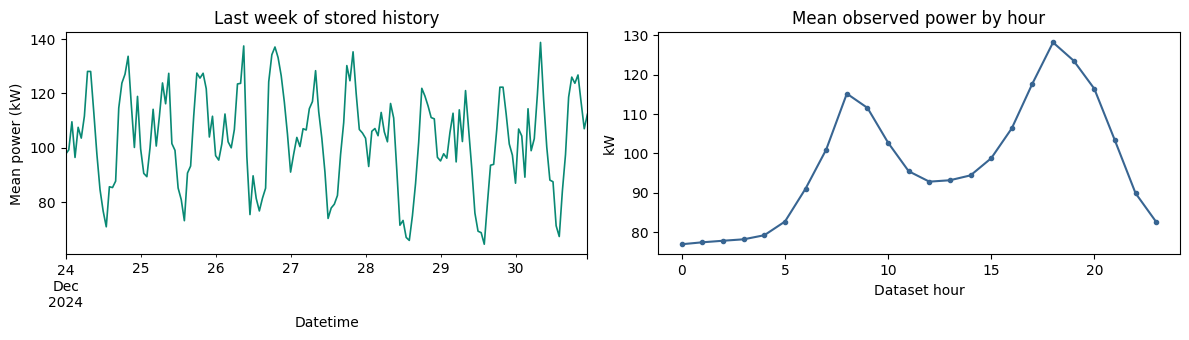

In [4]:
fig, axes = plt.subplots(1,2,figsize=(12,3.5))
frame.Energy_kW.tail(168).plot(ax=axes[0],color='#098974',lw=1.2,title='Last week of stored history')
axes[0].set_ylabel('Mean power (kW)')
obs = frame.loc[frame.target_observed,'Energy_kW']
obs.groupby(obs.index.hour).mean().plot(ax=axes[1],color='#386592',marker='o',ms=3,title='Mean observed power by hour')
axes[1].set(xlabel='Dataset hour',ylabel='kW')
plt.tight_layout(); plt.show()

## 4. Engineer past-only features

The model gets known cyclic calendar features, demand lags 1/2/24/48/168 and shifted rolling statistics. Current realized temperature/occupancy are **not** assumed available for future hours. The most important line is `past = energy.shift(1)` before rolling.

At time *t*, changing the target at *t* or later must not change its input features.

In [5]:
from src.features import build_features, next_feature_row
X, y = build_features(frame)
print('Eligible samples:',len(X),'| Features:',len(X.columns))
display(X.head(3).round(3))
t = X.index[100]
history = frame.loc[:t-pd.Timedelta(hours=1),'Energy_kW']
np.testing.assert_allclose(next_feature_row(t,history).values,X.loc[[t]].values,atol=1e-10)
changed = frame.copy()
changed.loc[t:,'Energy_kW'] = 99999.0
X_changed, _ = build_features(changed)
np.testing.assert_allclose(X.loc[t],X_changed.loc[t])
print('PASS: feature parity and no current/future target leakage.')

Eligible samples: 17266 | Features: 15


,hour_sin,hour_cos,dow_sin,dow_cos,doy_sin,doy_cos,is_weekend,lag_1,lag_2,lag_24,lag_48,lag_168,rolling_mean_24,rolling_std_24,rolling_mean_168
Datetime,,,,,,,,,,,,,,,
2023-01-08 00:00:00,0.000,1.000,-0.782,0.623,0.137,0.991,1.0,102.457,100.785,96.416,99.223,93.110,98.146,16.578,102.557
2023-01-08 01:00:00,0.259,0.966,-0.782,0.623,0.137,0.991,1.0,94.192,102.457,101.170,104.096,100.619,98.053,16.594,102.563
2023-01-08 02:00:00,0.500,0.866,-0.782,0.623,0.137,0.991,1.0,95.838,94.192,98.233,101.013,92.797,97.831,16.586,102.535


PASS: feature parity and no current/future target leakage.


## 5. Split by time, not at random

Earlier train → middle validation → latest test. Percentages apply to eligible observed supervised rows, so gaps can affect calendar durations. Scalers/estimators fit only on their allowed segment.

In [6]:
from src.evaluation import chronological_split
splits = chronological_split(X,y)
rows=[]
for name, (xx,yy) in splits.items():
    rows.append({'split':name,'rows':len(yy),'start':str(yy.index.min()),'end':str(yy.index.max())})
display(pd.DataFrame(rows))
assert splits['train'][0].index.max() < splits['validation'][0].index.min()
assert splits['validation'][0].index.max() < splits['test'][0].index.min()

,split,rows,start,end
0,train,12086,2023-01-08 00:00:00,2024-05-28 03:00:00
1,validation,2590,2024-05-28 04:00:00,2024-09-13 11:00:00
2,test,2590,2024-09-13 12:00:00,2024-12-30 23:00:00


## 6. Fit a simple model so you understand the mechanics

This educational cell fits **Ridge on train only** and prints a validation **one-step** score. It is not the champion-selection routine. The full pipeline chooses on validation **24-hour recursive RMSE**, comparing all six candidates. It is normal for these tasks to differ.

In [7]:
from src.models import fit_candidate, predict_rows
X_train,y_train=splits['train']; X_val,y_val=splits['validation']
ridge_spec,seconds,warnings = fit_candidate('ridge',X_train,y_train)
ridge_val = compute_metrics(y_val,predict_rows(ridge_spec,X_val))
print('Fresh educational Ridge fit — validation one-step only:')
display(pd.Series(ridge_val).round(4))
print('Scaler fit rows:',len(X_train),'| fit seconds:',round(seconds,3))

Fresh educational Ridge fit — validation one-step only:


n           2590.0000
mae_kw         6.5298
rmse_kw        8.3615
r2             0.9159
mape_pct       6.5494
wape_pct       6.3229
dtype: float64

Scaler fit rows: 12086 | fit seconds: 0.008


## 7. Inspect the actual full-run model comparison

The champion is locked on validation before test evaluation. On the measured UCI dataset, MLP happens to beat RF on the sampled test day-ahead windows. RF stays selected because it won validation: changing it after viewing test would be cherry-picking.

A one-step replay receives true lags every hour; a fixed-origin 24-hour forecast recursively receives its own predictions.

In [8]:
comparison=pd.read_csv(path('outputs',RUN,'model_comparison.csv'))
cols=['label','selected','validation_day_ahead_rmse_kw','test_day_ahead_rmse_kw','test_one_step_rmse_kw','test_day_ahead_r2']
display(comparison[cols].round(4))
print('Validation-selected:',metrics['selected_model_label'])
print('Test one-step:',metrics['test_one_step'])
print('Test day-ahead:',metrics['test_day_ahead'])
print('R² is NOT percentage accuracy. Origins:',metrics['test_backtest_origins'])

,label,selected,validation_day_ahead_rmse_kw,test_day_ahead_rmse_kw,test_one_step_rmse_kw,test_day_ahead_r2
0,Previous-hour baseline,False,39.5657,17.3387,11.0249,-0.0847
1,Yesterday baseline,False,11.5671,10.3670,9.4345,0.6122
2,Last-week baseline,False,11.0638,9.0638,8.7830,0.7036
3,Ridge regression,False,8.6829,7.2047,6.9590,0.8127
4,Random forest,False,8.6082,7.1929,6.8450,0.8133
5,MLP neural network,True,8.1974,6.8880,6.7108,0.8288


Validation-selected: MLP neural network
Test one-step: {'n': 2590, 'mae_kw': 5.344160476673637, 'rmse_kw': 6.710780296450444, 'r2': 0.8308364788013451, 'mape_pct': 5.832567827738372, 'wape_pct': 5.644477865736464}
Test day-ahead: {'n': 335, 'mae_kw': 5.485373913132413, 'rmse_kw': 6.887978329402054, 'r2': 0.8288172467840778, 'mape_pct': 6.093482233560431, 'wape_pct': 5.857645747792191}
R² is NOT percentage accuracy. Origins: 14


## 8. Recompute scores from saved held-out predictions

This verifies that README metrics have backing evidence. Imputed/unobserved truth is blank and not scored. Fourteen sampled origins do not mean every test day, nor seven-day accuracy.

PASS: stored day-ahead RMSE matches actual prediction CSV.


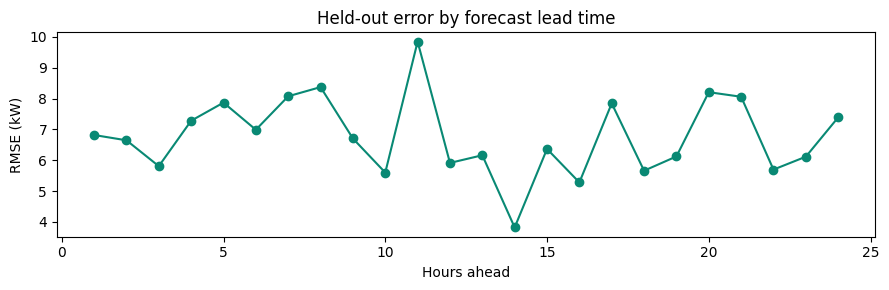

In [9]:
backtest=pd.read_csv(path('outputs',RUN,'backtest_predictions.csv'))
recomputed=compute_metrics(backtest.actual_kw,backtest.predicted_kw)
assert np.isclose(recomputed['rmse_kw'],metrics['test_day_ahead']['rmse_kw'],atol=1e-5)
print('PASS: stored day-ahead RMSE matches actual prediction CSV.')
horizons=pd.read_csv(path('outputs',RUN,'horizon_metrics.csv'))
ax=horizons.plot(x='horizon',y='rmse_kw',color='#098974',marker='o',figsize=(9,3),legend=False,title='Held-out error by forecast lead time')
ax.set(xlabel='Hours ahead',ylabel='RMSE (kW)');plt.tight_layout();plt.show()

## 9. Forecast genuine future hours from the final bundle

The selected model was refit on all historical data **after** held-out reporting. It is served only for timestamps after the final cutoff. Do not score this final refit on its own historical training/test period. The band is a descriptive pooled validation error radius, not guaranteed coverage, and stops after 24 h.

Cutoff: 2024-12-30 23:00:00 | first future hour: 2024-12-31 00:00:00
Next 24 h energy: 2543.53 kWh


,horizon,predicted_kw,predicted_kwh,lower_kw,upper_kw
Datetime,,,,,
2024-12-31 00:00:00,1,104.116,104.116,90.454,117.779
2024-12-31 01:00:00,2,101.943,101.943,88.280,115.605
2024-12-31 02:00:00,3,102.833,102.833,89.171,116.495
2024-12-31 03:00:00,4,102.738,102.738,89.076,116.401
2024-12-31 04:00:00,5,102.762,102.762,89.100,116.424


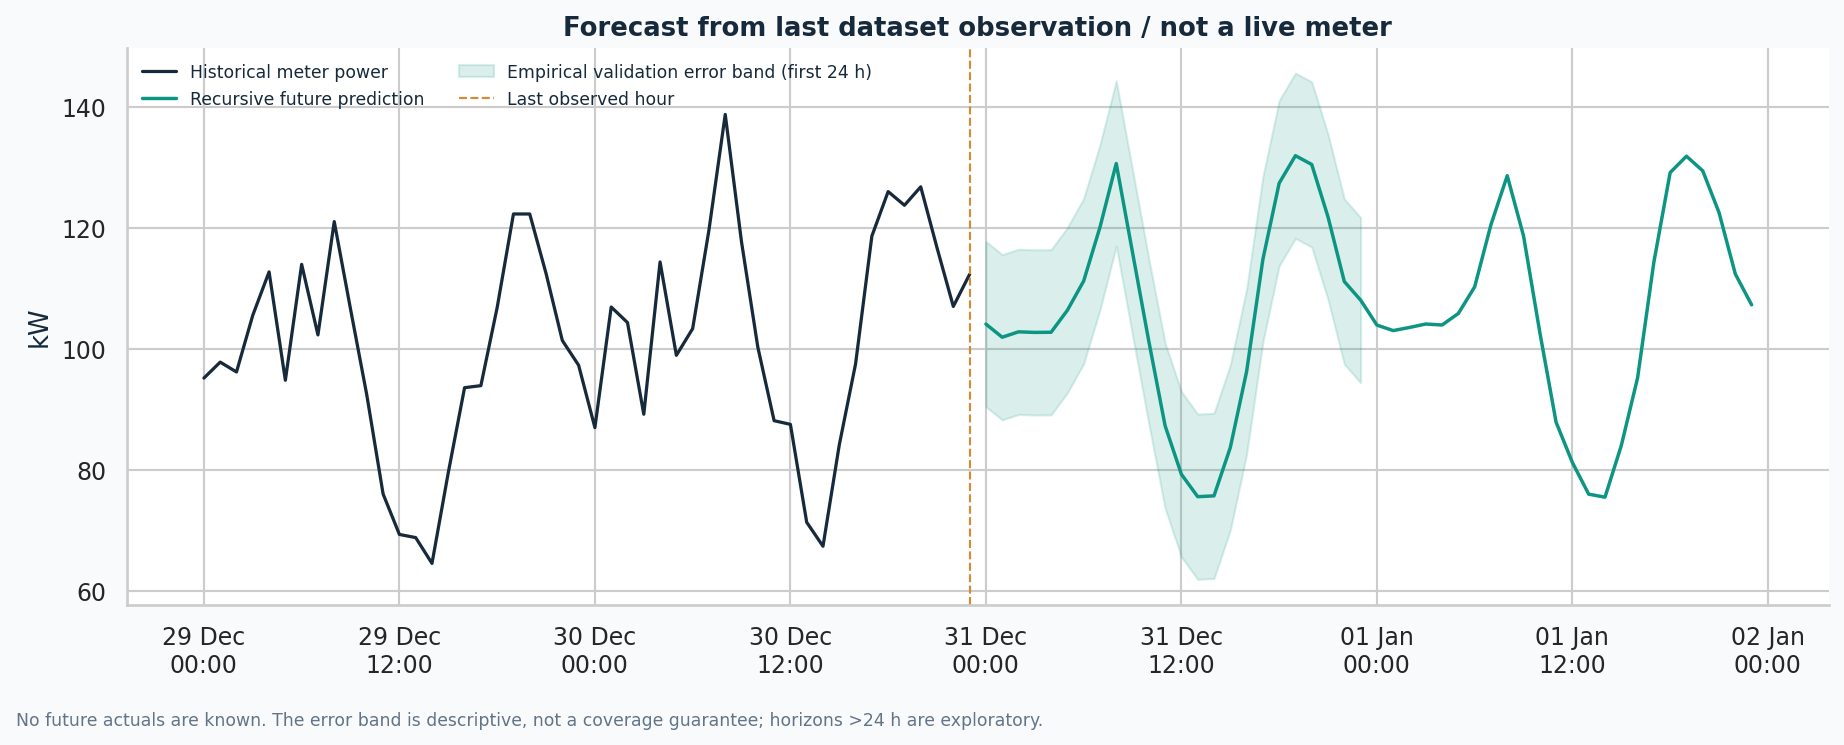

In [10]:
from src.forecast import load_bundle, forecast_bundle
bundle=load_bundle(RUN)
future=forecast_bundle(bundle,48)
print('Cutoff:',bundle['cutoff'],'| first future hour:',future.index[0])
print('Next 24 h energy:',round(future.predicted_kwh.iloc[:24].sum(),2),'kWh')
assert future.index[0] > pd.Timestamp(bundle['cutoff'])
assert future.lower_kw.iloc[24:].isna().all()
display(future.head().round(3))
display(Image(filename=str(path('images',RUN,'forecast.png'))))

## 10. Virtual business decision: shift flexible work, conserve energy

Illustrative INR rates and a flexible share are assumptions, not an actual tariff or savings outcome. The heuristic allows pre-scheduling/deferral within the 24 h window and respects original peak headroom. It does not model comfort, equipment, taxes or forecast risk.

With constant carbon intensity and unchanged kWh, modeled CO₂ reduction is **zero**.

In [11]:
from src.simulation import simulate
scenario_frame,scenario=simulate(future,{'flexible_fraction':0.10})
keys=['baseline_energy_kwh','shifted_energy_kwh','moved_energy_kwh','baseline_cost_inr',
      'shifted_cost_inr','hypothetical_savings_inr','hypothetical_savings_pct','emissions_reduction_kg']
display(pd.Series({k:scenario[k] for k in keys}).round(3))
assert np.isclose(scenario['baseline_energy_kwh'],scenario['shifted_energy_kwh'])
assert scenario['emissions_reduction_kg']==0
print('ASSUMPTIONS:');print(chr(10).join(scenario['assumptions']))

baseline_energy_kwh          2543.529
shifted_energy_kwh           2543.529
moved_energy_kwh               62.651
baseline_cost_inr           20991.895
shifted_cost_inr            20553.341
hypothetical_savings_inr      438.554
hypothetical_savings_pct        2.089
emissions_reduction_kg          0.000
dtype: float64

ASSUMPTIONS:
Illustrative INR time-of-use rates; not a real utility tariff or billing quote.
10% of peak-hour forecast load flexible by default; configurable 0-50%.
Pre-scheduling/deferral allowed anywhere inside this 24-hour window.
All shifted load fits original forecast peak headroom; no equipment constraints modeled.
No demand charges, taxes, rebound, discomfort or forecast error in cost calculation.
Constant illustrative carbon intensity: shifting preserves energy and does NOT reduce modeled emissions.
Savings are simulated, not measured or guaranteed.


## 11. Test the same API without starting another long-running server

A Flask test client exercises the real route/model code locally. For a visible UI run `python app.py` in a terminal. A browser GET endpoint differs from a JSON POST. The old hour/day-only payload is intentionally rejected because lag history is required.

In [12]:
from app import app
with app.test_client() as client:
    response=client.post('/predict',json={'dataset':RUN,'hours':24})
    assert response.status_code==200
    result=response.get_json()
    print('Real route response:',result['model'],result['cutoff'],len(result['predictions']),'hours')
    display(pd.DataFrame(result['predictions']).head())
    invalid=client.post('/predict',json={'hour':14,'day':2})
    print('Insufficient context correctly rejected:',invalid.status_code)

Real route response: mlp 2024-12-30 23:00:00 24 hours


,Datetime,horizon,predicted_kw,predicted_kwh,lower_kw,upper_kw
0,2024-12-31 00:00:00,1,104.116458,104.116458,90.454169,117.778748
1,2024-12-31 01:00:00,2,101.942503,101.942503,88.280214,115.604793
2,2024-12-31 02:00:00,3,102.832791,102.832791,89.170501,116.495080
3,2024-12-31 03:00:00,4,102.738340,102.738340,89.076050,116.400629
4,2024-12-31 04:00:00,5,102.761836,102.761836,89.099547,116.424126


Insufficient context correctly rejected:

 400


## 12. Compare both completed source experiments

Do not compare absolute kW RMSE as though a large virtual building and one household have the same scale. The measured house's day-ahead WAPE is high; this is an honest limitation, not operational readiness.

In [13]:
summary=[]
for run_id in ['synthetic','uci']:
    metric_file=path('outputs',run_id,'metrics.json')
    if metric_file.exists():
        m=load_json(metric_file)
        summary.append({'source':run_id,'selected':m['selected_model_label'],
                        'day_ahead_rmse_kw':m['test_day_ahead']['rmse_kw'],
                        'day_ahead_wape_pct':m['test_day_ahead']['wape_pct'],
                        'one_step_r2':m['test_one_step']['r2']})
display(pd.DataFrame(summary).round(4))

,source,selected,day_ahead_rmse_kw,day_ahead_wape_pct,one_step_r2
0,synthetic,MLP neural network,6.8880,5.8576,0.8308
1,uci,Random forest,0.5982,48.4370,0.5671


## 13. Turn the learning into honest proof

1. Run `python -m pytest -q` and inspect `outputs/test-results.txt`.
2. Run `python scripts/validate_project.py`.
3. Study the actual graphs and source hashes, not just the dashboard.
4. Make one documented train/validation experiment in a separate branch/run.
5. Publish your real repository and capture its actual URL/CI status.
6. Explain assistance and personal contributions honestly; no backdated seven-day history or corporate claims.

Full guide: `docs/PROJECT_GUIDE.md`. Data/model cards, scenario assumptions, claims audit and interview notes are also included.

**Useful exercise:** what changes if flexible share is 0? Why is modeled CO₂ unchanged at 20%? How would you add weather forecasts without future-information leakage?